# Sea Level Rise Model

This notebook builds the lattice that represents uncertain sea level rise and learning about it (thesis Chapter 4).

A lattice has a set of sea level rise states at every time step $t$ (every 10 years) and transition probabilities between the states of consecutive time steps. A decision maker observes the current state; the transition probabilities then give the distribution of future sea level rise. This is how the model represents **learning**. The marginal distribution of the states at every time step must match the quantile function $Q_t$ of the data (`Data.ipynb`).

The **Direct fit method** (used in the thesis, adapted from Völz et al. 2023b, thesis Section 4.3) fits a recombining binomial lattice. At time step $t$ it has $t + 1$ states. Each state moves up with probability $p$ or down with probability $1 - p$. The states are placed at the quantiles $Q_t(q)$, where $q$ is the midpoint of the binomial CDF interval of each state.

Two other learning models serve as references (thesis Section 4.2 and Appendix A4):
- **Static grid**: every state can follow every state, i.e., no learning.
- **Linear growth**: the first transition picks a constant rate of sea level rise, i.e., all uncertainty is resolved at once.

## Implementation

A `SeaLevelRiseModel` fits $Q_t$ and builds its lattice when it is created; `model.lattice` holds the states and transitions:

```python
model = DirectFitSeaLevelRiseModel(start_year=2020, end_year=2140, step=10, method="mixture", distribution=None, weights=[0.25, 0.5, 0.25], extrapolate=True)
model.lattice.states(t)                          # states at time step t [m], t in years after start_year
model.lattice.get_transition_probs(t, state, None)  # [(probability, next state), ...]
trajectories = list(model.sample_trajectories(500, seed=42))
```

This notebook uses the lattice 2020-2140 of the thesis figures. `Decision_Analysis.ipynb` uses the same lattice with the decisions at the middle of each time step (2025-2145).

In [1]:
from source.sea_level_rise_model import (
    DirectFitSeaLevelRiseModel,
    LinearGrowthSeaLevelRiseModel,
    StaticGridSeaLevelRiseModel,
    plot_conditioned_lattice,
    plot_direct_fit_construction,
    plot_lattice,
    plot_lattice_and_boxplots,
    plot_lattice_boxplot_comparison,
    plot_trajectories,
    plot_trajectory,
    print_lattice,
)

calibration = {
    "start_year": 2020,
    "end_year": 2140,
    "step": 10,  # Time step [yr]
    "method": "mixture",
    "distribution": None,  # Pearson type IV
    "weights": [0.25, 0.5, 0.25],  # Scenario weights w
    "extrapolate": True,
    "align_to_lattice_midpoint": False,
}

## Direct Fit Method

Illustration with two time steps: the states (left) are read from the quantile function at the midpoints of their probability intervals (right).

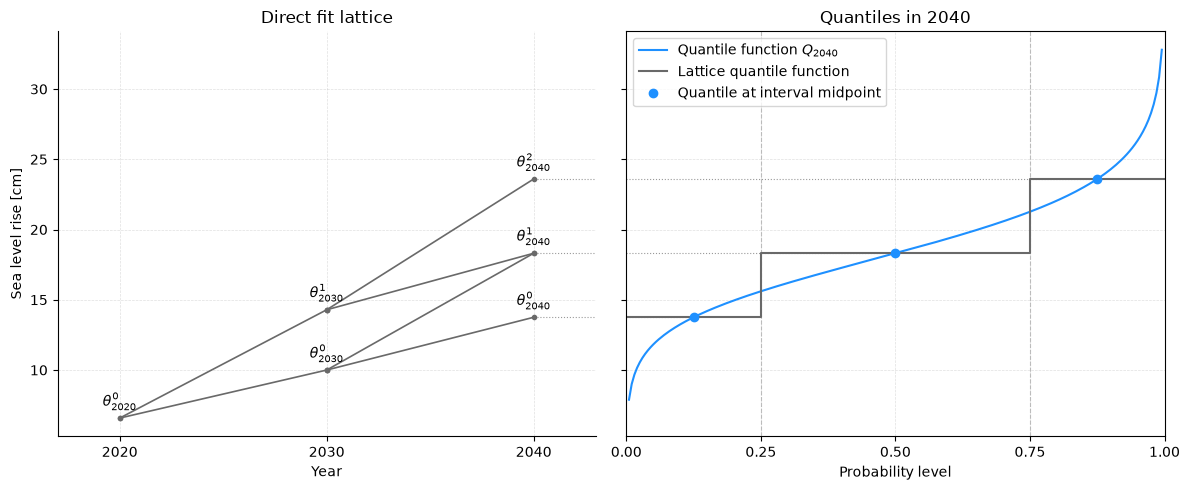

In [2]:
_ = plot_direct_fit_construction(DirectFitSeaLevelRiseModel(**{**calibration, "end_year": calibration["start_year"] + 2 * calibration["step"]}, p=0.5))

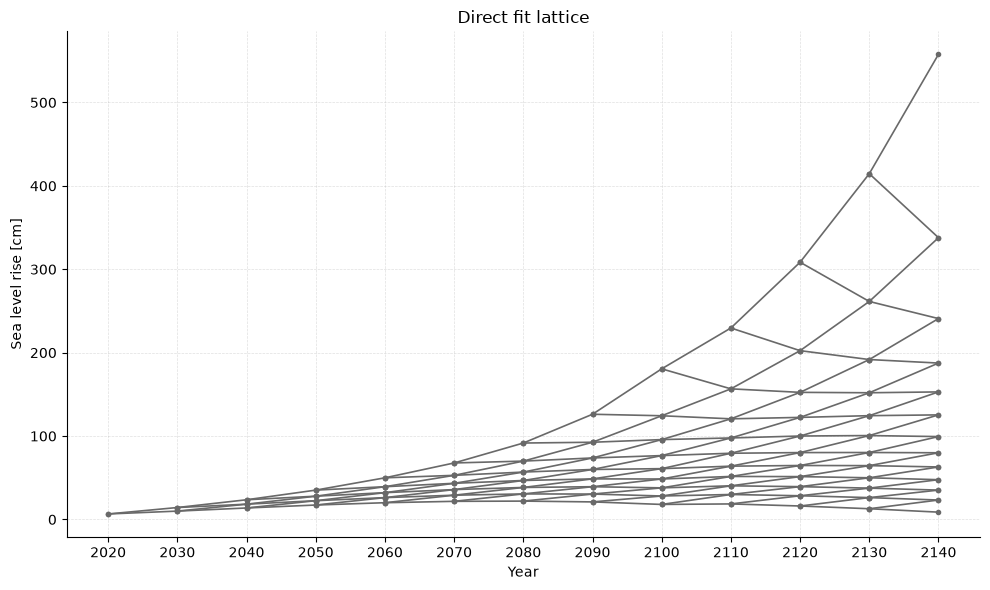

In [3]:
direct_fit_model = DirectFitSeaLevelRiseModel(**calibration, p=0.5)
_ = plot_lattice(direct_fit_model, label="", title="Direct fit lattice")

## Validation

The marginal distribution of the lattice compared with the quantile function of the data.

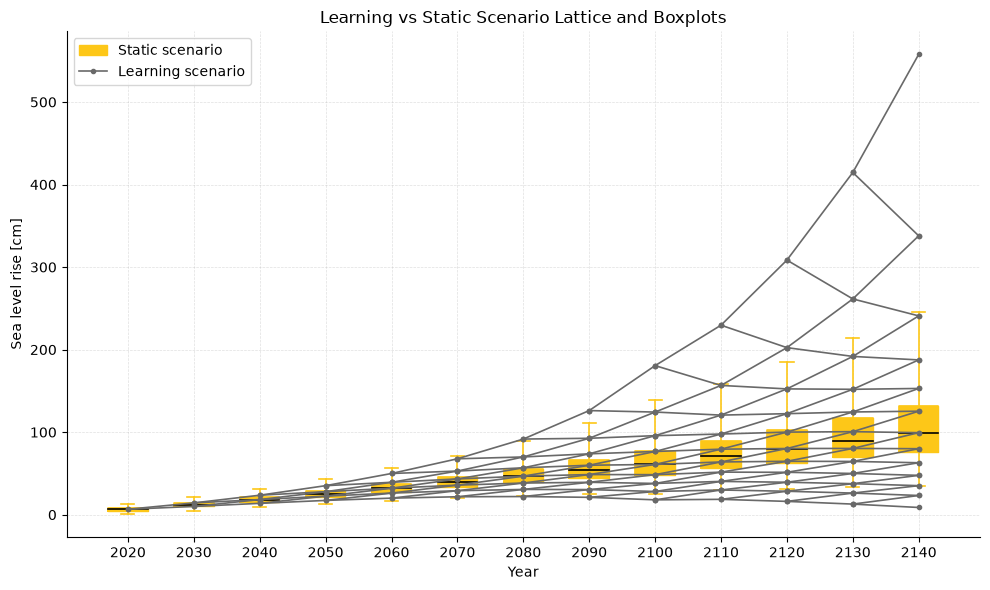

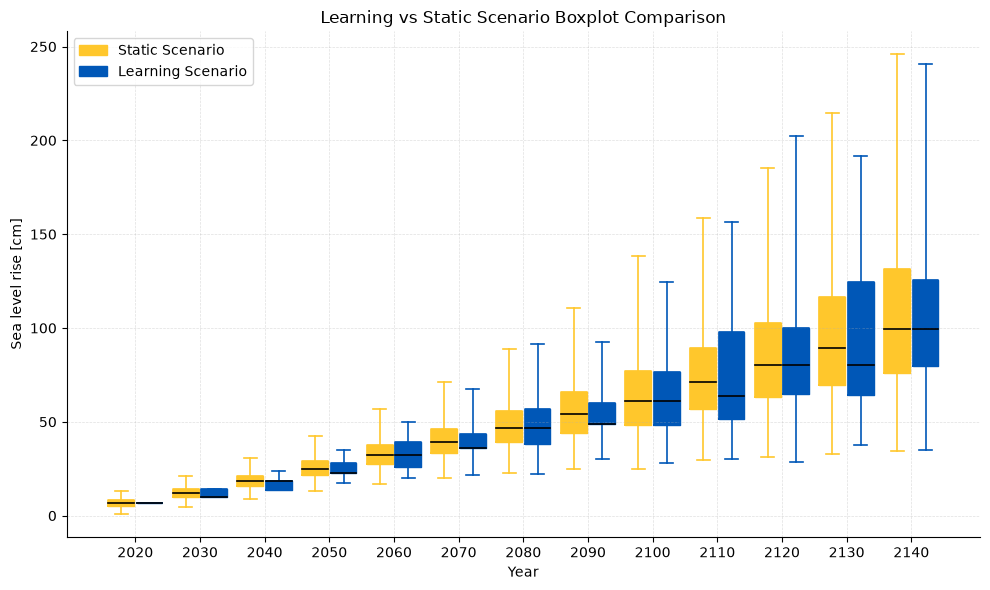

In [4]:
_ = plot_lattice_and_boxplots(direct_fit_model)
_ = plot_lattice_boxplot_comparison(direct_fit_model)

## Learning

Conditioning the lattice on an observation (here 0.5 m in 2090) narrows the distribution of future sea level rise. Sampled trajectories show possible observations.

Closest observed state at observed year:  48.63 cm


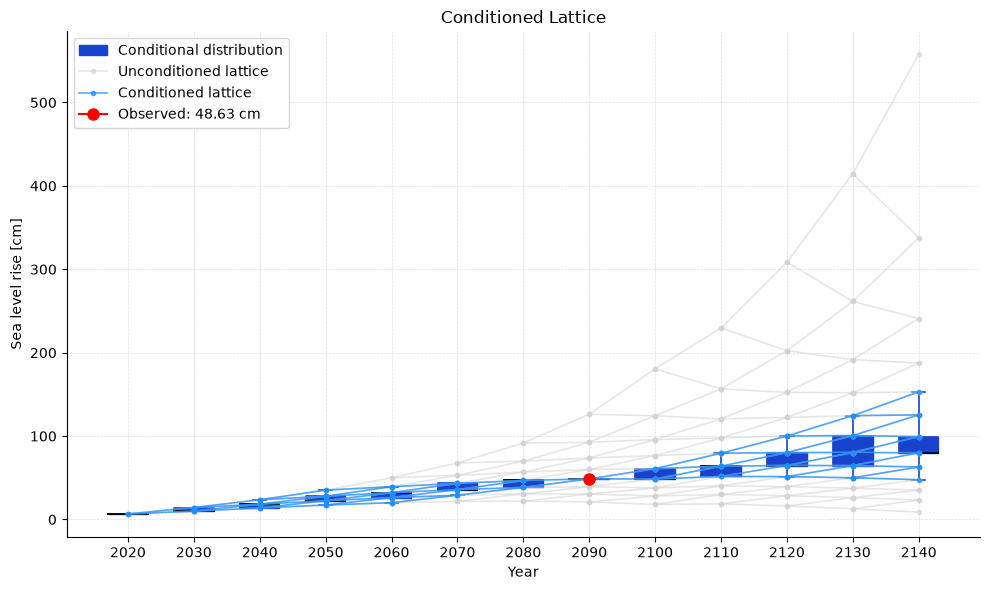

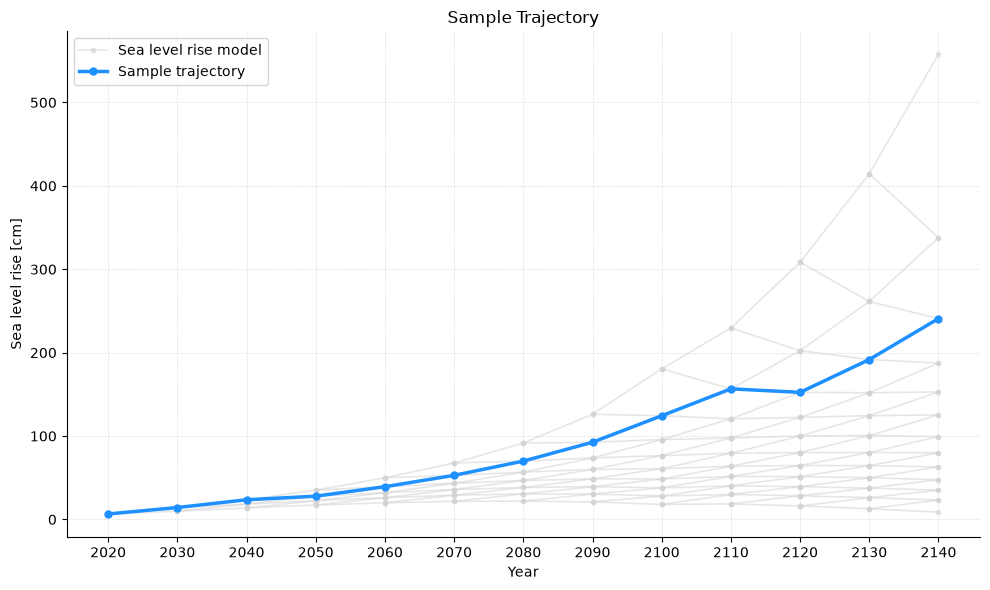

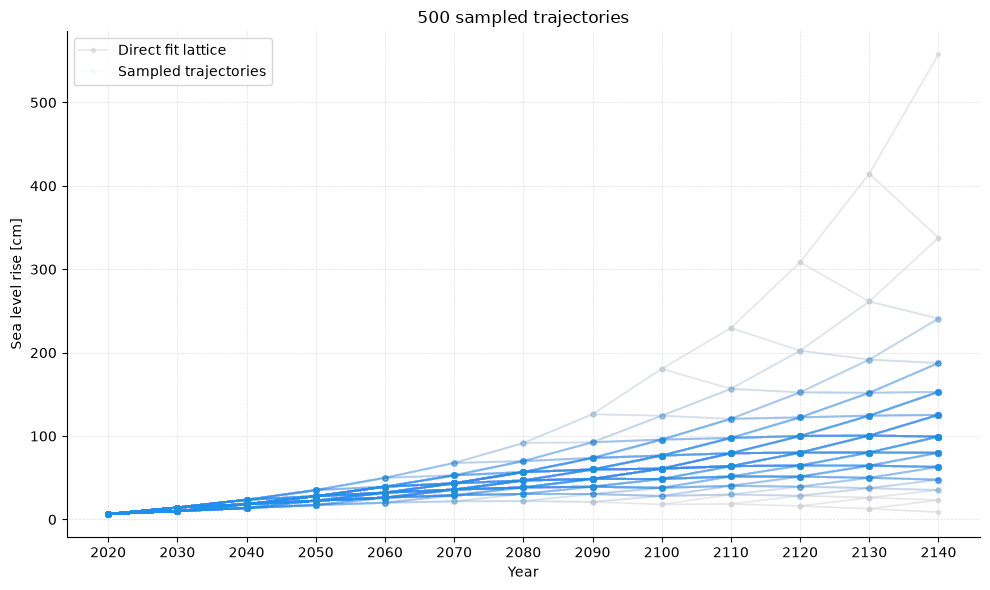

In [5]:
_ = plot_conditioned_lattice(direct_fit_model, observed_year=70, observed_state=0.5, plot_distributions=True)

samples = list(direct_fit_model.sample_trajectories(100_000, seed=42))
_ = plot_trajectory(direct_fit_model, trajectory=samples[202])
_ = plot_trajectories(direct_fit_model, trajectories=samples[:500], alpha=0.02, title="500 sampled trajectories")

## Static Grid and Linear Growth

The two reference learning models with the same calibration.

Closest observed state at observed year:  51.50 cm
Closest observed state at observed year:  49.38 cm


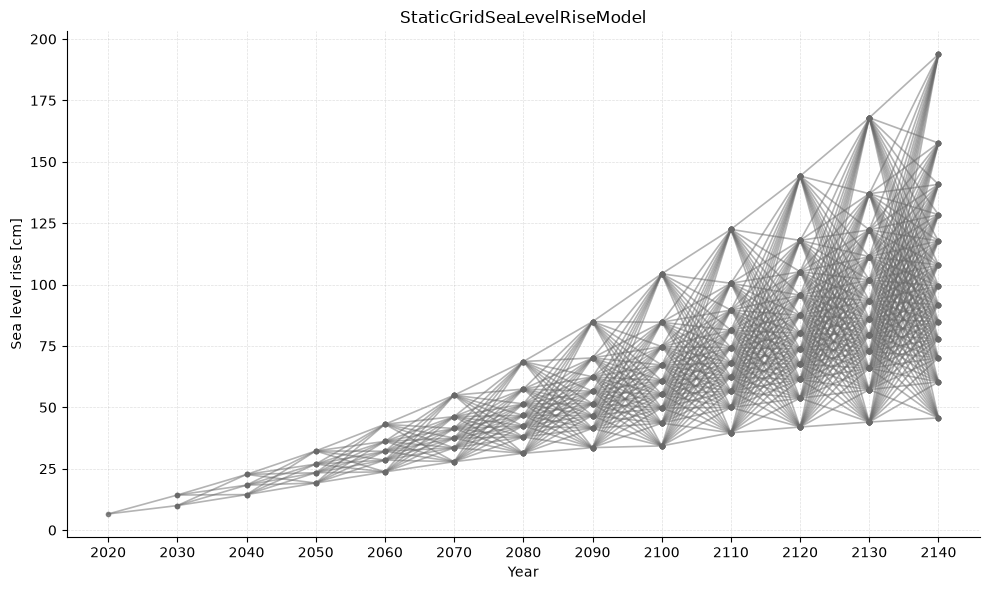

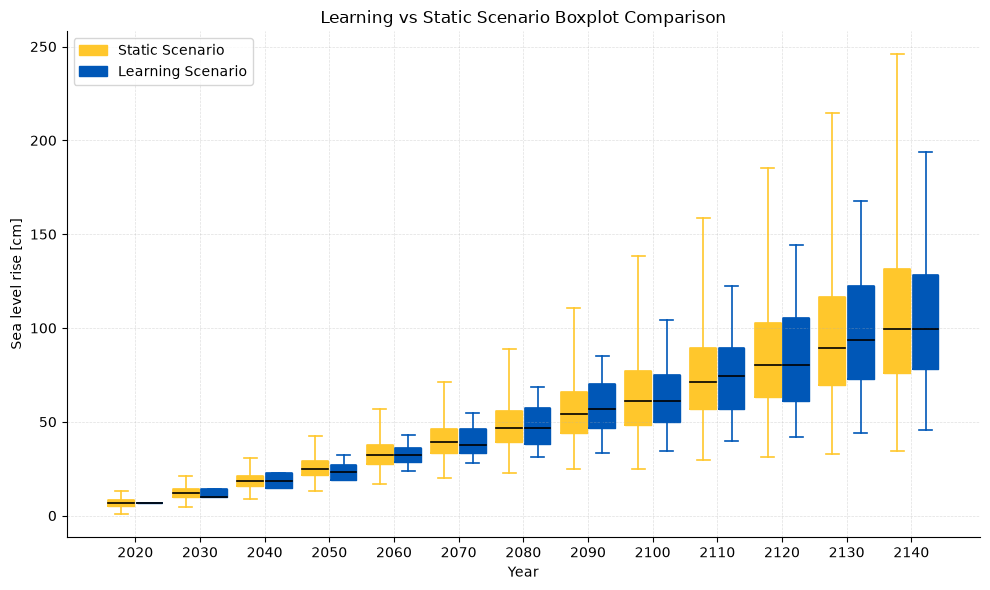

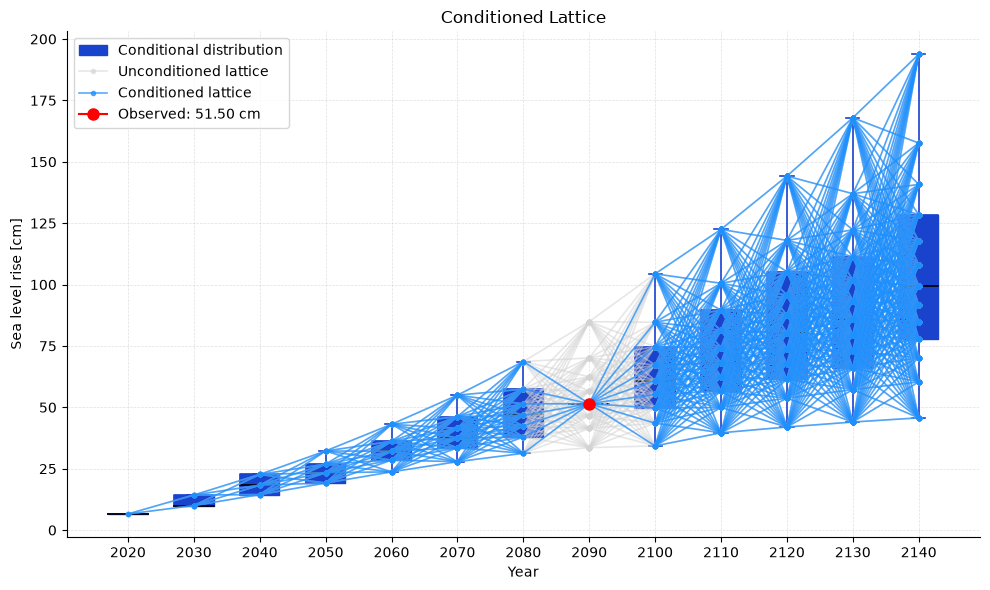

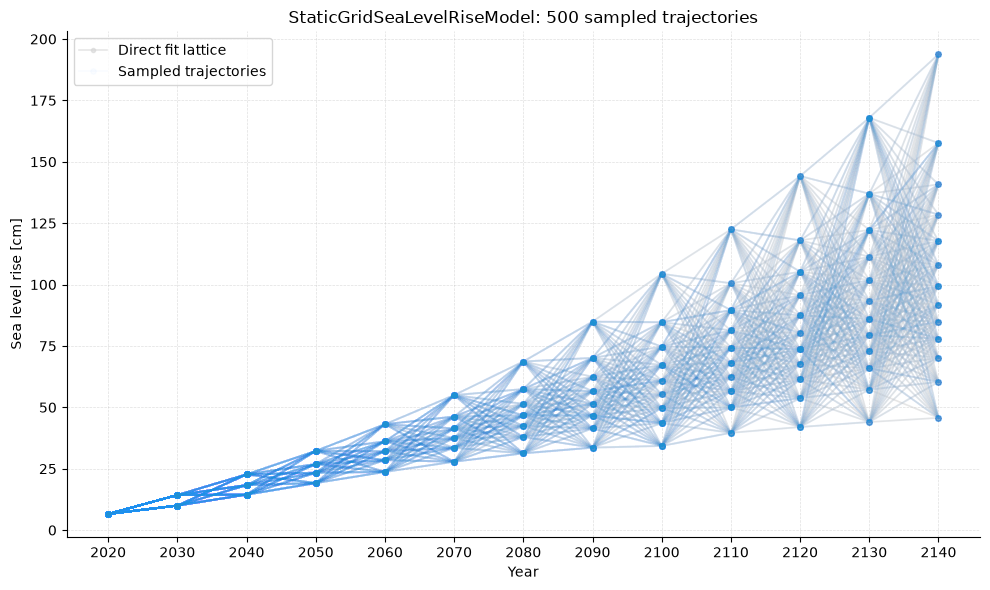

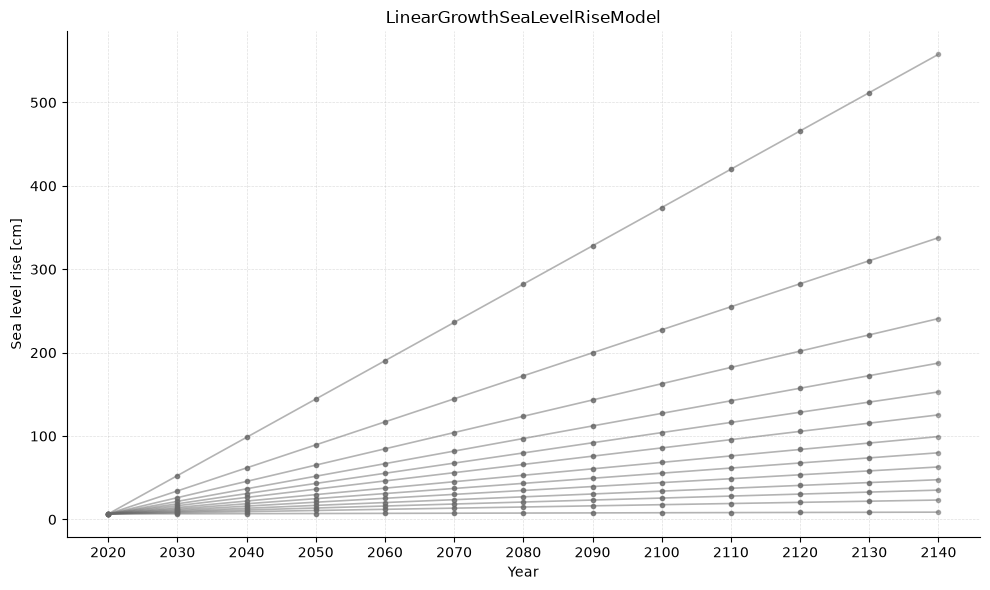

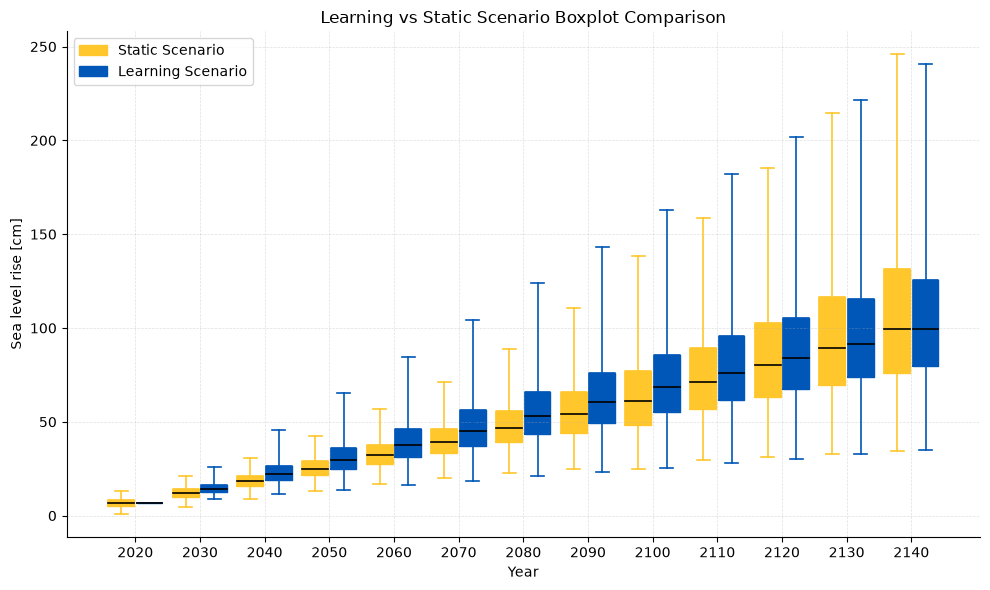

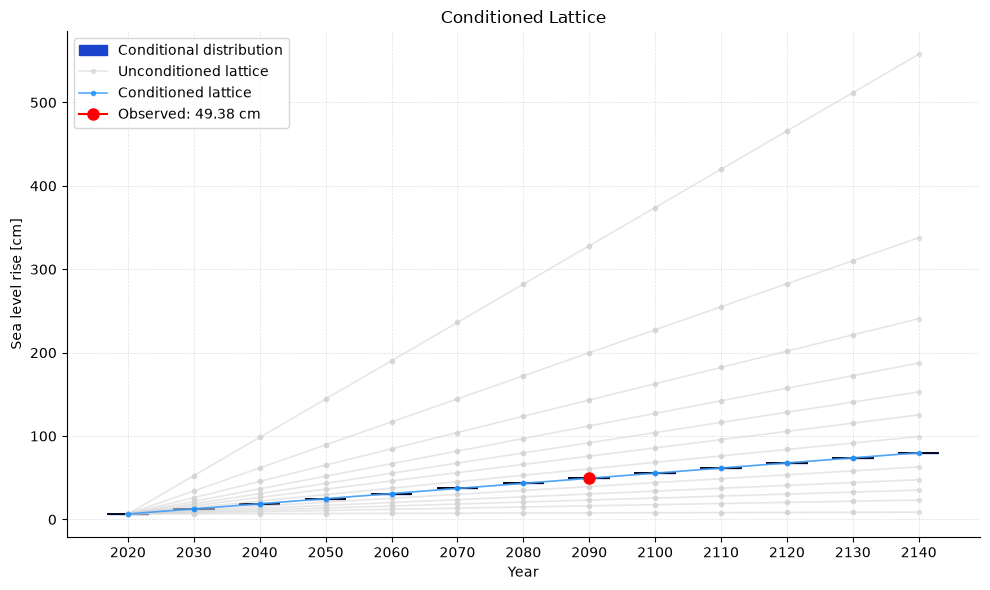

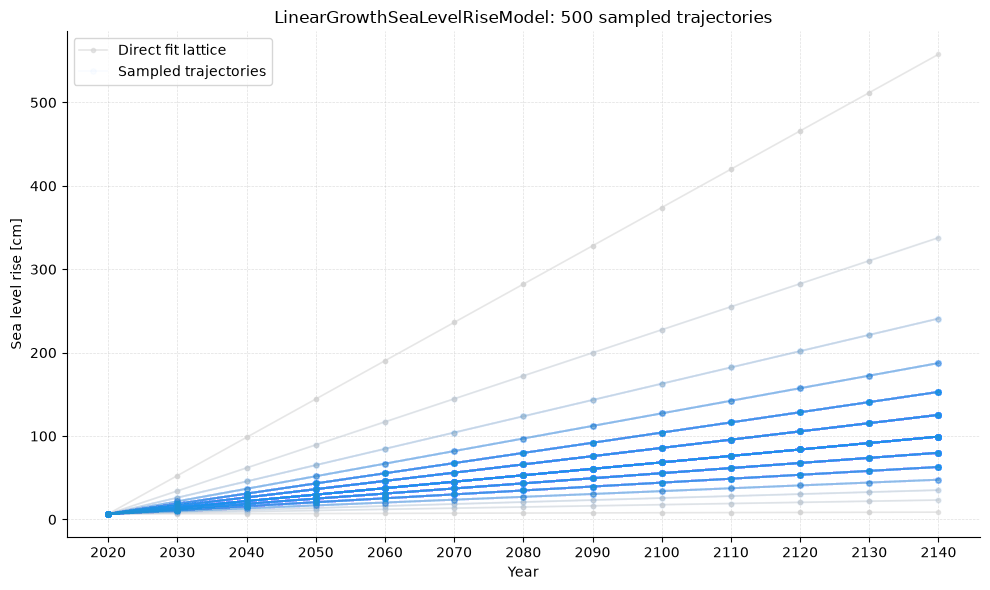

In [6]:
for model in (StaticGridSeaLevelRiseModel(**calibration), LinearGrowthSeaLevelRiseModel(**calibration)):
    name = type(model).__name__
    _ = plot_lattice(model, title=name, alpha=0.5)
    _ = plot_lattice_boxplot_comparison(model)
    _ = plot_conditioned_lattice(model, observed_year=70, observed_state=0.5, plot_distributions=True)
    _ = plot_trajectories(model, trajectories=list(model.sample_trajectories(500, seed=42)), alpha=0.02, title=f"{name}: 500 sampled trajectories")